# Kalman Filter Pinpoint Analysis

Insert code and relevant libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_excel("data/EE_Pinpoint_Data_RAW.xlsx")

Compute the canonical coordinates

In [2]:
data["True X Coordinate"] = 24 * round(data["X Coordinate "] / 24)
data["True Y Coordinate"] = 24 * round(data["Y Coordinate"] / 24)
data["True Heading"] = 0

Compute covariance matrix

In [3]:
data["X Error"] = data["True X Coordinate"] - data["X Coordinate "]
data["Y Error"] = data["True Y Coordinate"] - data["Y Coordinate"]
data["Heading Error"] = data["True Heading"] - data["Heading"]

errors = data[["X Error", "Y Error", "Heading Error"]]

covariance = errors.cov()
print(covariance)

                X Error   Y Error  Heading Error
X Error        0.333230  0.006894       0.000964
Y Error        0.006894  0.235371      -0.000150
Heading Error  0.000964 -0.000150       0.000153


Validation

In [4]:
bound = 1e-9

assert abs(data["X Error"].var() - covariance.iloc[0].iloc[0]) <= bound
assert abs(data["Y Error"].var() - covariance.iloc[1].iloc[1]) <= bound
assert abs(data["Heading Error"].var() - covariance.iloc[2].iloc[2]) <= bound


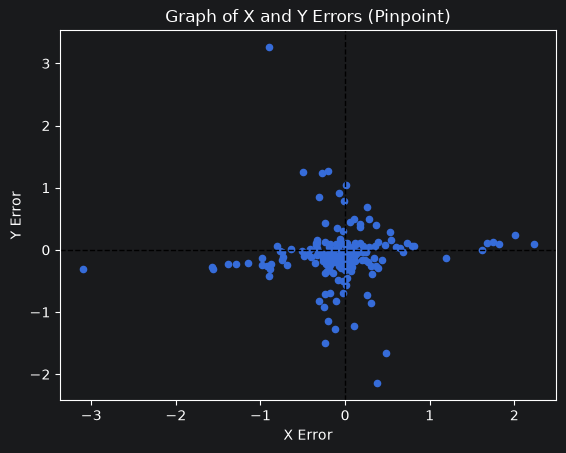

In [7]:
graph = data.plot.scatter(x = "X Error", y = "Y Error", title="Graph of X and Y Errors (Pinpoint)")

graph.axhline(0, color="black", linestyle="--", linewidth=1)
graph.axvline(0, color="black", linestyle="--", linewidth=1)

plt.show()

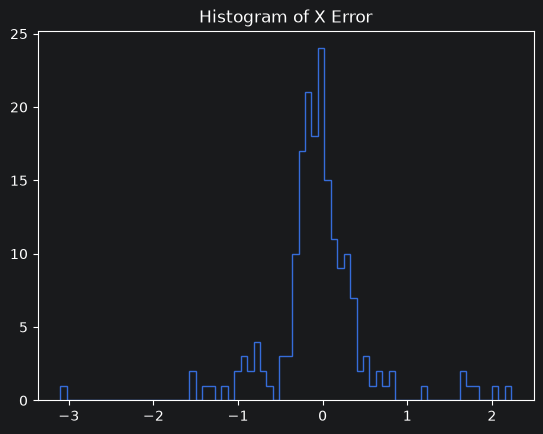

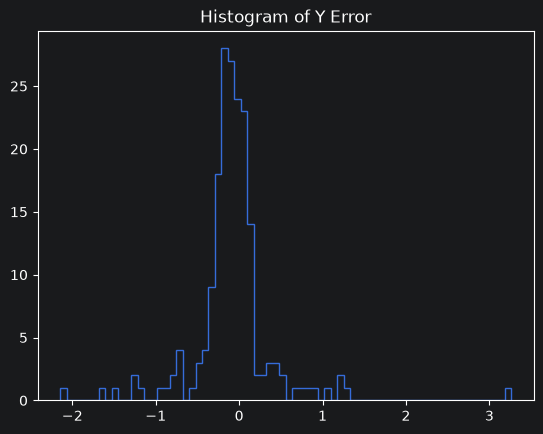

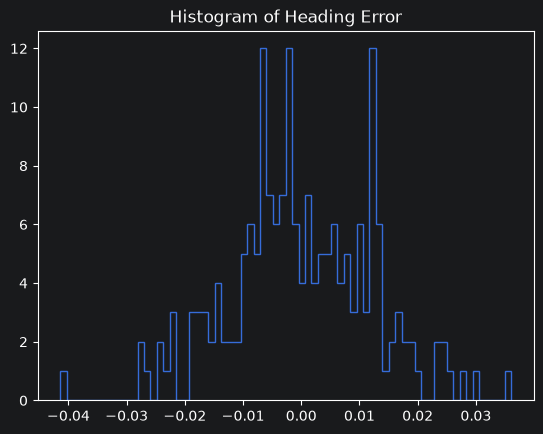

In [6]:
count, bins = np.histogram(data["X Error"], bins=70)

fig, ax = plt.subplots()
ax.stairs(count, bins)
ax.set_title("Histogram of X Error")
plt.show()

count, bins = np.histogram(data["Y Error"], bins=70)

fig, ax = plt.subplots()
ax.stairs(count, bins)
ax.set_title("Histogram of Y Error")
plt.show()

count, bins = np.histogram(data["Heading Error"], bins=70)

fig, ax = plt.subplots()
ax.stairs(count, bins)
ax.set_title("Histogram of Heading Error")
plt.show()